# OpenCV Crash Course: 2026 Edition
## Module 2: Image Processing
**Estimated time: 40-50 minutes**

---

### What you'll learn
- Blurring / smoothing (Gaussian, Median, Bilateral)
- Thresholding (Binary, Otsu, Adaptive)
- Edge detection (Canny)
- Morphological operations (erosion, dilation, opening, closing)
- Histogram equalization & CLAHE

> These are the core building blocks for **every** computer vision pipeline.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show(img, title="", figsize=(7, 5)):
    plt.figure(figsize=figsize)
    if len(img.shape) == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap='gray')
    plt.title(title, fontsize=13)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

def show_grid(images, titles, cols=3, figsize=(15, 5)):
    rows = (len(images) - 1) // cols + 1
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.array(axes).flatten()
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 3:
            axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            axes[i].imshow(img, cmap='gray')
        axes[i].set_title(title, fontsize=11)
        axes[i].axis('off')
    for j in range(len(images), len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()

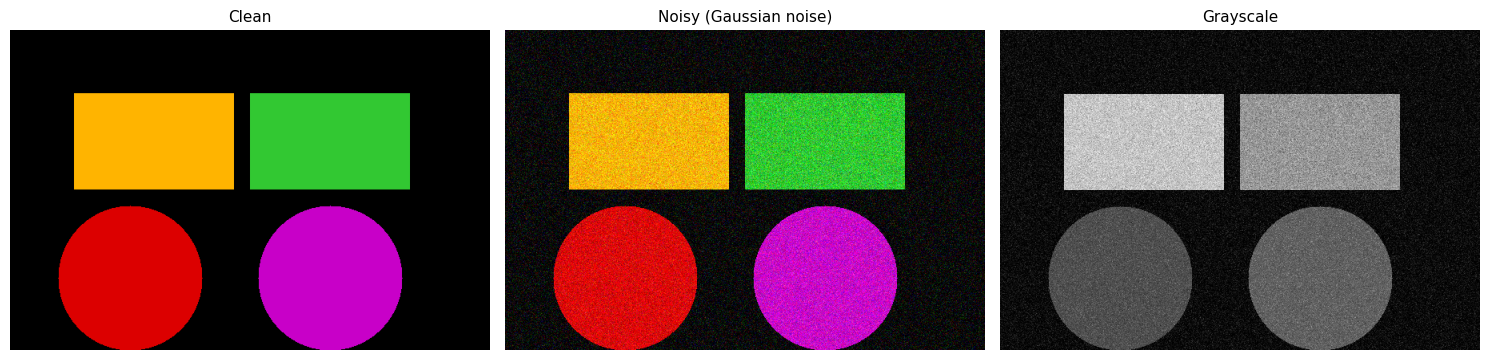

In [3]:
# Create a noisy test image
base = np.zeros((400, 600, 3), dtype=np.uint8)
base[80:200, 80:280]   = (0, 180, 255)    # orange rect
base[80:200, 300:500]  = (50, 200, 50)    # green rect
cv2.circle(base, (150, 310), 90, (0, 0, 220), -1)  # red circle
cv2.circle(base, (400, 310), 90, (200, 0, 200), -1) # purple circle

# Add Gaussian noise
noise = np.random.normal(0, 30, base.shape).astype(np.int16)
img_noisy = np.clip(base.astype(np.int16) + noise, 0, 255).astype(np.uint8)

# Grayscale version for thresholding demos
gray = cv2.cvtColor(img_noisy, cv2.COLOR_BGR2GRAY)

show_grid([base, img_noisy, gray],
          ["Clean", "Noisy (Gaussian noise)", "Grayscale"])

## 1. Blurring / Smoothing

Blurring **removes noise** and is often the first step before edge detection or thresholding.

| Method | Best for |
|--------|----------|
| Average blur | Fast, simple smoothing |
| Gaussian blur | General purpose - most common |
| Median blur | Salt-and-pepper noise |
| Bilateral | Smooth noise **but preserve edges** |

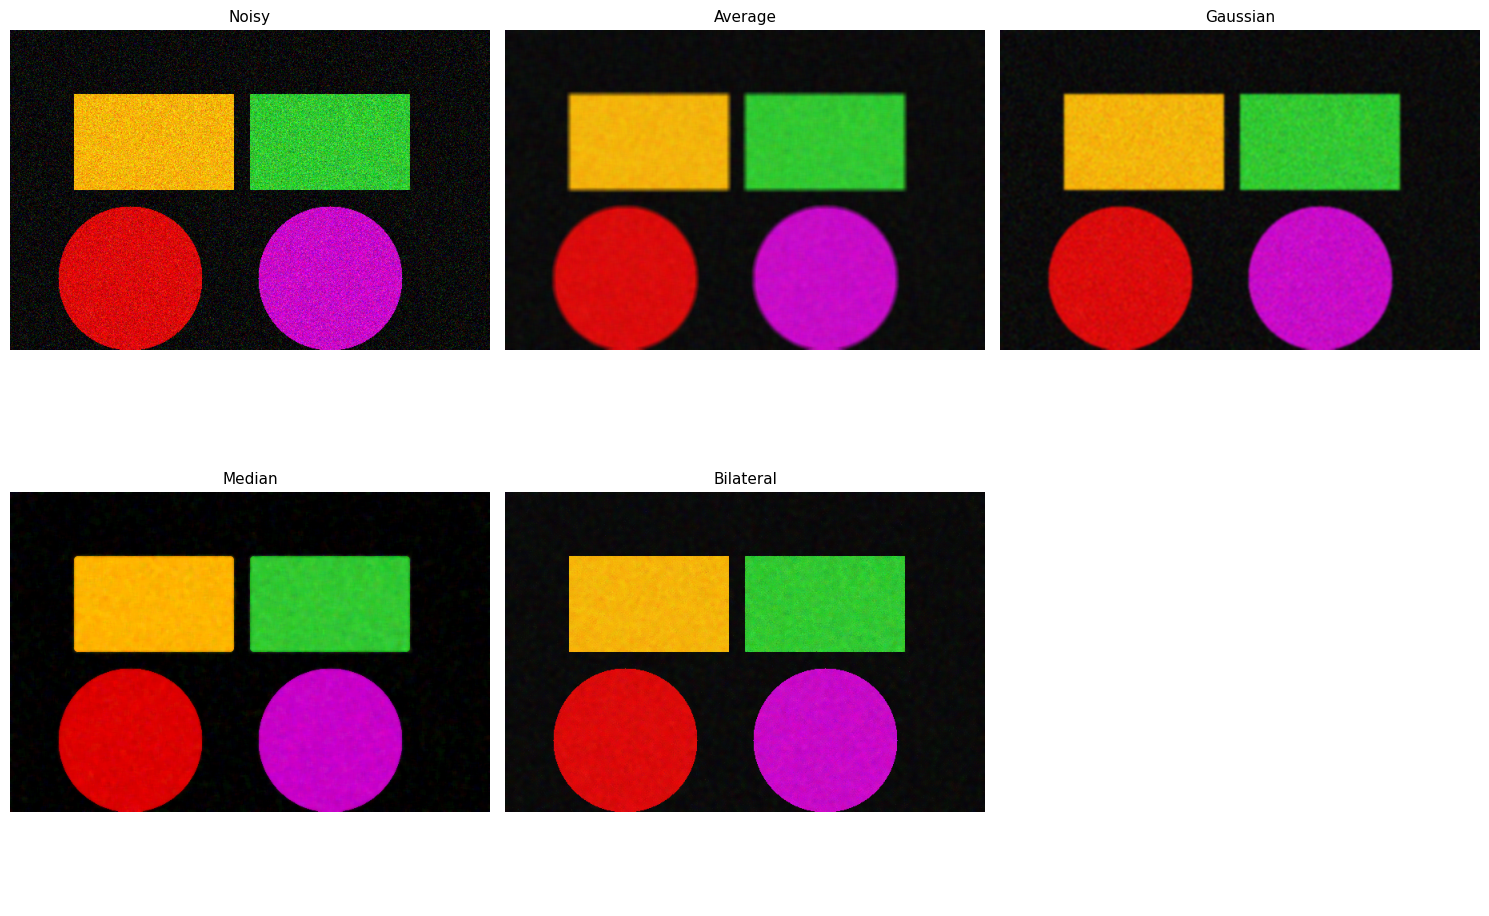

In [4]:
blur_avg      = cv2.blur(img_noisy, (7, 7))
blur_gaussian = cv2.GaussianBlur(img_noisy, (7, 7), sigmaX=0)
blur_median   = cv2.medianBlur(img_noisy, 7)           # ksize must be odd
blur_bilateral= cv2.bilateralFilter(img_noisy, d=9, sigmaColor=75, sigmaSpace=75)

show_grid(
    [img_noisy, blur_avg, blur_gaussian, blur_median, blur_bilateral],
    ["Noisy", "Average", "Gaussian", "Median", "Bilateral"],
    cols=3, figsize=(15, 10)
)

## 2. Thresholding

Thresholding turns a grayscale image into a **binary (black/white) mask**.  
Essential for separating objects from backgrounds.

- **Simple** - one global threshold value
- **Otsu** - automatically finds the best threshold
- **Adaptive** - different threshold for each local region (handles uneven lighting)

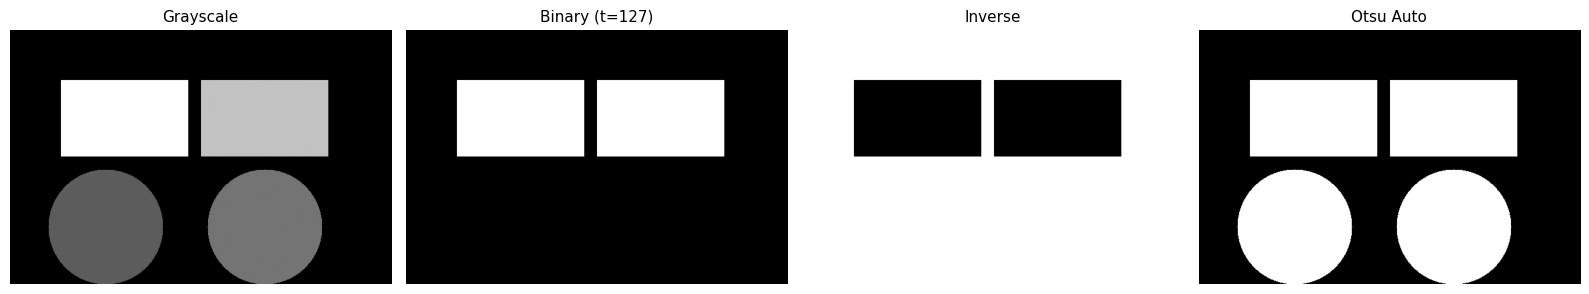

In [6]:
gray_clean = cv2.cvtColor(base, cv2.COLOR_BGR2GRAY)

# Simple threshold: pixels > 127 become white, rest black
_, thresh_binary = cv2.threshold(gray_clean, 127, 255, cv2.THRESH_BINARY)

# Inverse
_, thresh_inv    = cv2.threshold(gray_clean, 127, 255, cv2.THRESH_BINARY_INV)

# Otsu - automatically picks the best threshold (great for bimodal histograms)
_, thresh_otsu   = cv2.threshold(gray_clean, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show_grid(
    [gray_clean, thresh_binary, thresh_inv, thresh_otsu],
    ["Grayscale", "Binary (t=127)", "Inverse", "Otsu Auto"],
    cols=4, figsize=(16, 4)
)

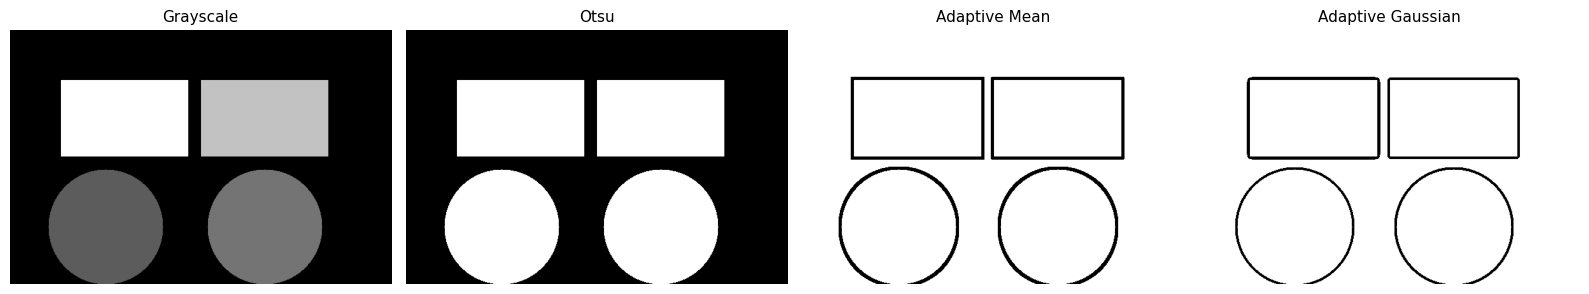

In [7]:
# Adaptive threshold - best when lighting is uneven
# blockSize: neighborhood size (must be odd)
# C: constant subtracted from mean
adaptive_mean   = cv2.adaptiveThreshold(gray_clean, 255,
                    cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 2)
adaptive_gauss  = cv2.adaptiveThreshold(gray_clean, 255,
                    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)

show_grid(
    [gray_clean, thresh_otsu, adaptive_mean, adaptive_gauss],
    ["Grayscale", "Otsu", "Adaptive Mean", "Adaptive Gaussian"],
    cols=4, figsize=(16, 4)
)

## 3. Edge Detection

**Canny** is the go-to edge detector. It:
1. Applies Gaussian blur
2. Computes gradient magnitude
3. Non-maximum suppression
4. Hysteresis thresholding with `threshold1` and `threshold2`

> Rule of thumb: `threshold2 = 2x or 3x threshold1`

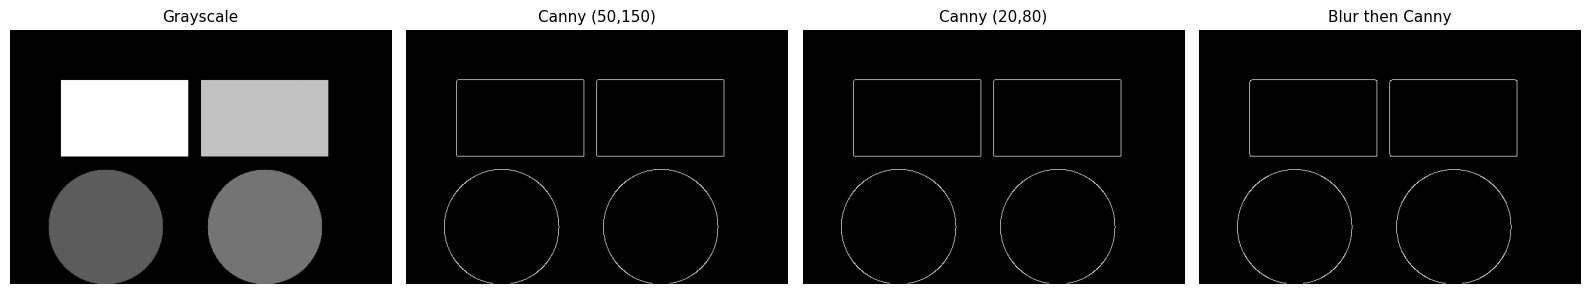

In [8]:
# Canny edge detection
edges_tight = cv2.Canny(gray_clean, 50,  150)   # stricter - fewer edges
edges_wide  = cv2.Canny(gray_clean, 20,  80)    # looser   - more edges
edges_blur  = cv2.Canny(cv2.GaussianBlur(gray_clean, (5,5), 0), 50, 150)

show_grid(
    [gray_clean, edges_tight, edges_wide, edges_blur],
    ["Grayscale", "Canny (50,150)", "Canny (20,80)", "Blur then Canny"],
    cols=4, figsize=(16, 4)
)

## 4. Morphological Operations

Work on **binary images** to remove noise, fill gaps, or separate objects.

| Operation | Effect |
|-----------|--------|
| Erosion | Shrinks white regions - removes small dots |
| Dilation | Grows white regions - fills small holes |
| Opening | Erosion → Dilation (removes small objects) |
| Closing | Dilation → Erosion (fills small holes) |
| Gradient | Dilation - Erosion (outlines) |

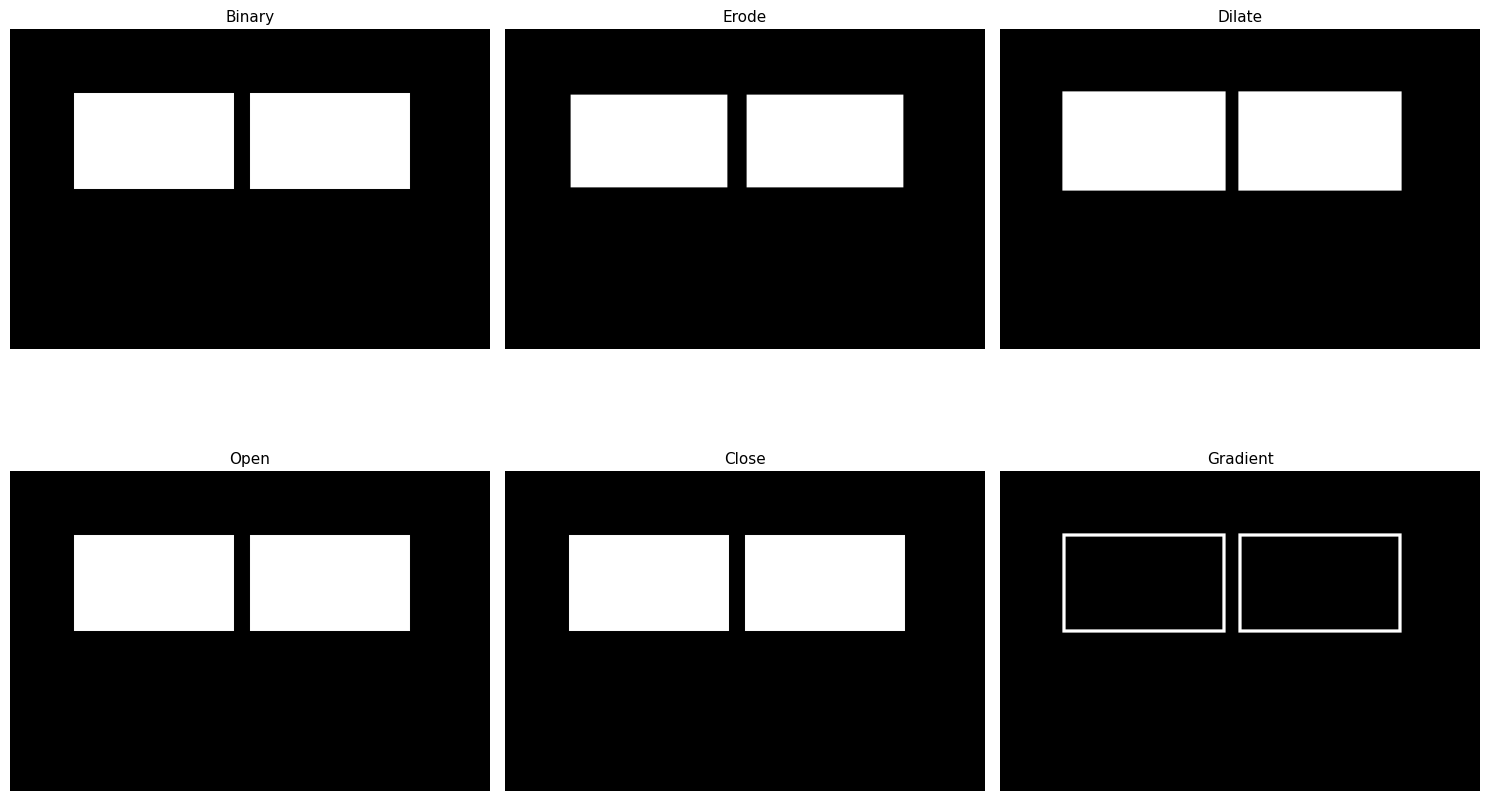

In [10]:
kernel = np.ones((5, 5), np.uint8)

eroded   = cv2.erode(thresh_binary, kernel, iterations=1)
dilated  = cv2.dilate(thresh_binary, kernel, iterations=1)
opened   = cv2.morphologyEx(thresh_binary, cv2.MORPH_OPEN,    kernel)
closed   = cv2.morphologyEx(thresh_binary, cv2.MORPH_CLOSE,   kernel)
gradient = cv2.morphologyEx(thresh_binary, cv2.MORPH_GRADIENT, kernel)

show_grid(
    [thresh_binary, eroded, dilated, opened, closed, gradient],
    ["Binary", "Erode", "Dilate", "Open", "Close", "Gradient"],
    cols=3, figsize=(15, 10)
)

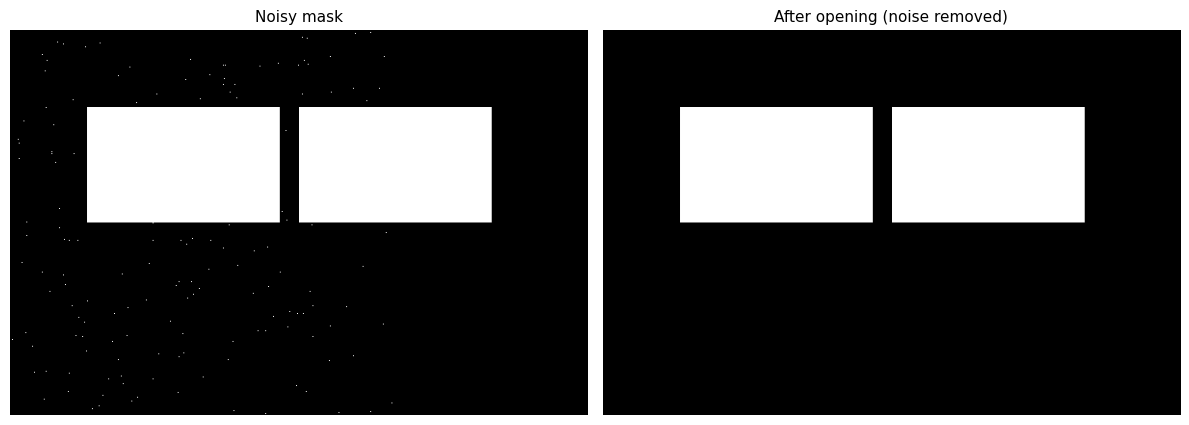

In [11]:
# Practical: remove small noise blobs from a mask
noisy_mask = thresh_binary.copy()
# Simulate noise
rng = np.random.default_rng(42)
noise_pts = rng.integers(0, noisy_mask.shape[0], size=(200, 2))
for pt in noise_pts:
    noisy_mask[pt[0], pt[1]] = 255

clean_kernel = np.ones((3, 3), np.uint8)
cleaned = cv2.morphologyEx(noisy_mask, cv2.MORPH_OPEN, clean_kernel, iterations=2)

show_grid([noisy_mask, cleaned], ["Noisy mask", "After opening (noise removed)"],
          cols=2, figsize=(12, 5))

## 5. Histogram & Contrast Enhancement

Histograms show the **distribution of pixel intensities**.  
Equalization stretches the histogram to improve low-contrast images.

C:\Users\Nidhi\AppData\Local\Temp\ipykernel_14924\209006450.py:21: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[1, col].hist(im.ravel(), 256, [0, 256], color='steelblue', alpha=0.8)


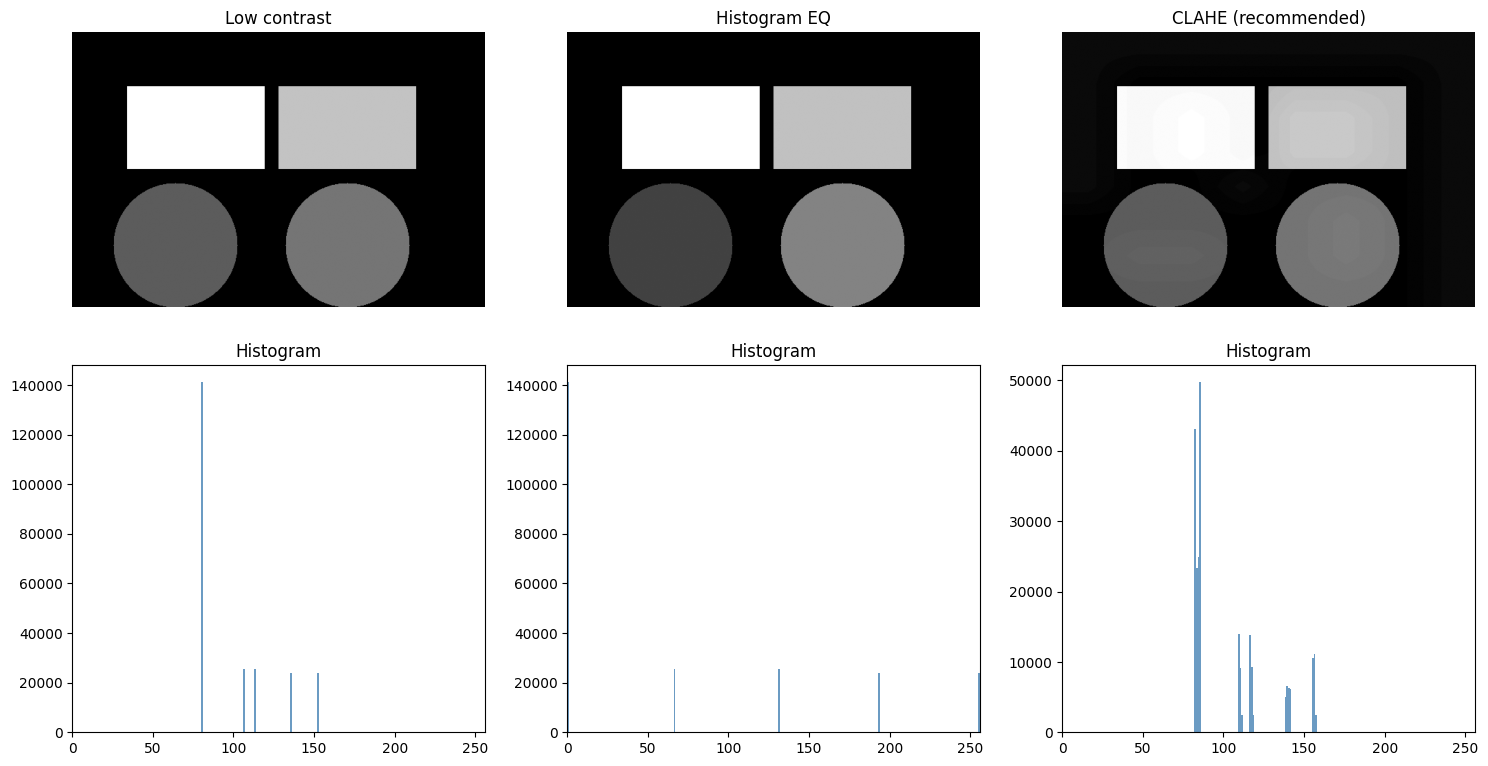

In [12]:
# Create a low-contrast image
low_contrast = (gray_clean * 0.4 + 80).astype(np.uint8)

# Histogram Equalization
eq = cv2.equalizeHist(low_contrast)

# CLAHE - Contrast Limited Adaptive HE (much better for real photos)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_img = clahe.apply(low_contrast)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
imgs_titles = [
    (low_contrast, "Low contrast"),
    (eq,           "Histogram EQ"),
    (clahe_img,    "CLAHE (recommended)")
]
for col, (im, t) in enumerate(imgs_titles):
    axes[0, col].imshow(im, cmap='gray')
    axes[0, col].set_title(t)
    axes[0, col].axis('off')
    axes[1, col].hist(im.ravel(), 256, [0, 256], color='steelblue', alpha=0.8)
    axes[1, col].set_xlim([0, 256])
    axes[1, col].set_title("Histogram")
plt.tight_layout()
plt.show()

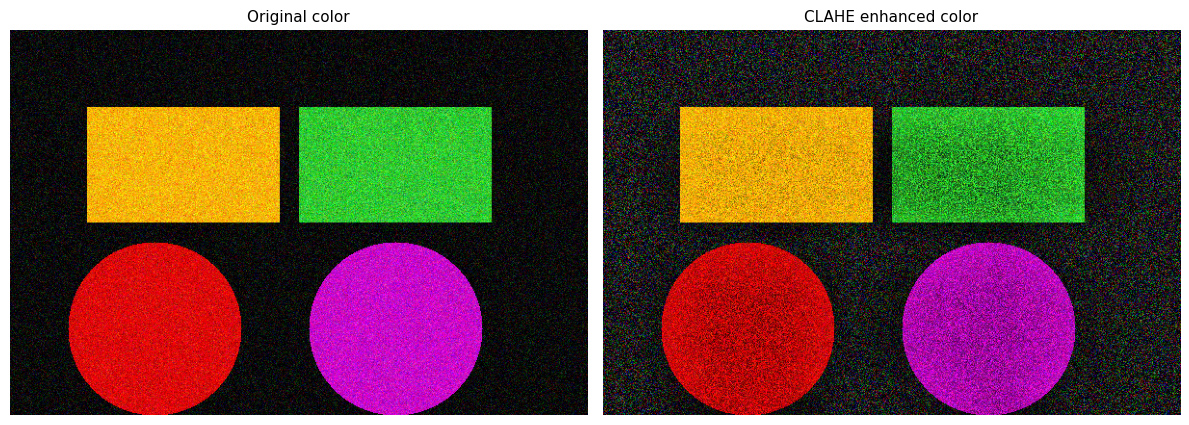

In [13]:
# CLAHE on a color image (apply only to V channel of HSV)
color_img = img_noisy.copy()
hsv = cv2.cvtColor(color_img, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)
v_clahe = clahe.apply(v)
hsv_clahe = cv2.merge([h, s, v_clahe])
result = cv2.cvtColor(hsv_clahe, cv2.COLOR_HSV2BGR)

show_grid([color_img, result], ["Original color", "CLAHE enhanced color"],
          cols=2, figsize=(12, 5))

---

## Module 2 Summary

| Task | Code |
|------|------|
| Gaussian blur | `cv2.GaussianBlur(img, (7,7), 0)` |
| Median blur | `cv2.medianBlur(img, 7)` |
| Bilateral (edge-preserving) | `cv2.bilateralFilter(img, 9, 75, 75)` |
| Otsu threshold | `cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)` |
| Adaptive threshold | `cv2.adaptiveThreshold(...)` |
| Canny edges | `cv2.Canny(gray, 50, 150)` |
| Erode / Dilate | `cv2.erode()` / `cv2.dilate()` |
| Open / Close | `cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel)` |
| CLAHE | `cv2.createCLAHE(2.0, (8,8)).apply(gray)` |

**Next:** Module 3 - Drawing & Contours